In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import classification_report

print("Downloading LFW dataset (this may take a moment)...")
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

n_samples, h, w = lfw_people.images.shape
X = lfw_people.data
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("\n--- Dataset Summary ---")
print(f"Total dataset size: {n_samples} images")
print(f"Features per image: {X.shape[1]} (flattened {h}x{w} pixels)")
print(f"Number of classes (people): {n_classes}")

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


--- Dataset Summary ---
Total dataset size: 1288 images
Features per image: 1850 (flattened 50x37 pixels)
Number of classes (people): 7


In [ ]:
# --- Task 2: Computing the Principal Components ---
n_components = 150
print(f"Extracting the top {n_components} eigenfaces from {X_train.shape[0]} faces...")
t0 = time.time()

# Initialize and fit the PCA model
pca = PCA(n_components=n_components, svd_solver='randomized', whiten=True).fit(X_train)
print(f"PCA fitting done in {time.time() - t0:.3f}s")

# Transform both X_train and X_test into the new reduced dimensional space
t0 = time.time()
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print(f"Data transformation done in {time.time() - t0:.3f}s")

Extracting the top 150 eigenfaces from 1030 faces...
PCA fitting done in 0.415s
Data transformation done in 0.060s



Plotting the top 12 Eigenfaces (most significant variance vectors):


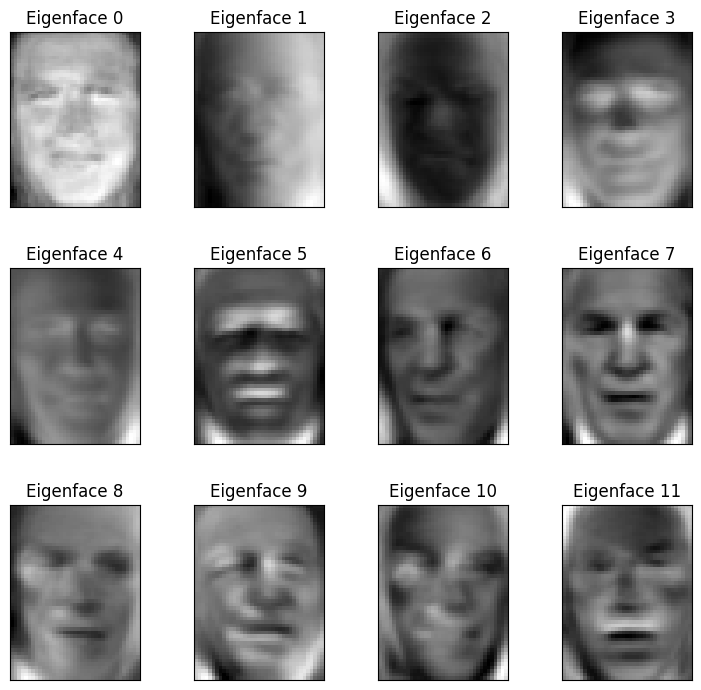

In [ ]:
# --- Task 3: Visualizing the Eigenfaces ---
eigenfaces = pca.components_.reshape((n_components, h, w))

def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i], cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
    plt.show()

eigenface_titles = [f"Eigenface {i}" for i in range(eigenfaces.shape[0])]
print("\nPlotting the top 12 Eigenfaces (most significant variance vectors):")
plot_gallery(eigenfaces, eigenface_titles, h, w)

In [ ]:
# --- Task 4: Face Recognition in the Reduced Space ---
print("Fitting the SVM classifier to the PCA training set...")
t0 = time.time()

clf = SVC(kernel='rbf', class_weight='balanced')
clf.fit(X_train_pca, y_train)
print(f"Classifier fitting done in {time.time() - t0:.3f}s")

print("Predicting people's names on the test set...")
y_pred = clf.predict(X_test_pca)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=target_names))

Fitting the SVM classifier to the PCA training set...
Classifier fitting done in 0.202s
Predicting people's names on the test set...

--- Classification Report ---
                   precision    recall  f1-score   support

     Ariel Sharon       1.00      0.64      0.78        11
     Colin Powell       0.62      0.96      0.75        47
  Donald Rumsfeld       0.89      0.73      0.80        22
    George W Bush       0.95      0.91      0.93       119
Gerhard Schroeder       0.94      0.89      0.92        19
      Hugo Chavez       1.00      0.54      0.70        13
       Tony Blair       0.95      0.74      0.83        27

         accuracy                           0.85       258
        macro avg       0.91      0.77      0.82       258
     weighted avg       0.89      0.85      0.86       258



Found 38 incorrect predictions. Visualizing the first 12 failures:


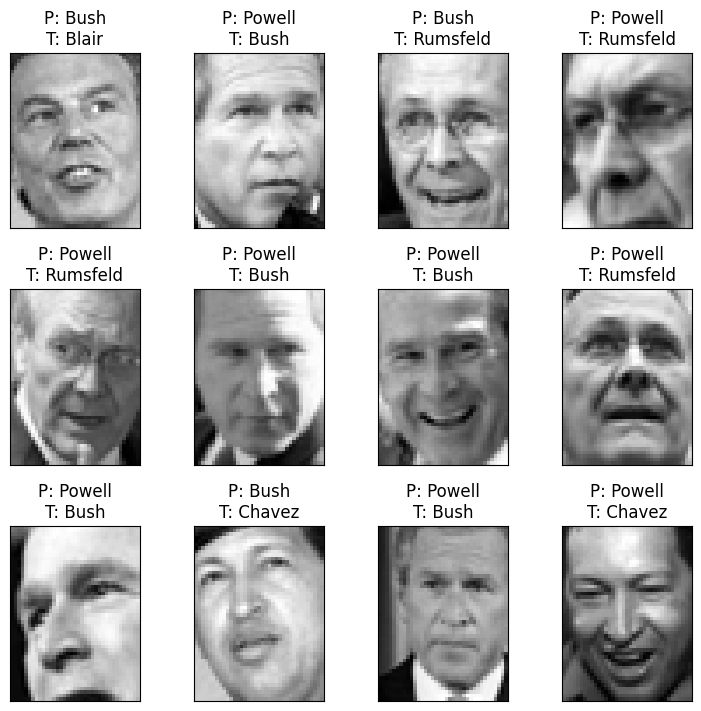

In [ ]:
# --- Post-Lab Analysis: Plotting Incorrect Predictions ---
incorrect_idx = np.where(y_pred != y_test)[0]

print(f"Found {len(incorrect_idx)} incorrect predictions. Visualizing the first 12 failures:")

def title_maker(y_pred, y_test, target_names, i):
    pred_name = target_names[y_pred[i]].rsplit(' ', 1)[-1]
    true_name = target_names[y_test[i]].rsplit(' ', 1)[-1]
    return f'P: {pred_name}\nT: {true_name}'

# Generate titles showing Predicted (P) vs True (T) names
prediction_titles = [title_maker(y_pred, y_test, target_names, i) for i in incorrect_idx]

# Plot the failed faces using the original X_test image data
plot_gallery(X_test[incorrect_idx].reshape(-1, h, w), prediction_titles, h, w)